<a href="https://colab.research.google.com/github/sessm216/Compu2324/blob/main/Schrodingersim_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1D Time-Dependent Schrödinger Equation: Physical Setup and Numerical Algorithm

This notebook summarises the lecture slides *"Resolución de ecuaciones en derivadas parciales: la ecuación de Schrödinger"* (Computational Physics). It is organised in two parts:

1. **Physical parameters of the simulation**: the equation, units, boundary conditions, initial wave function and potential.
2. **The algorithm**: why a naive scheme fails, the Cayley (Crank–Nicolson) unitary scheme, and the tridiagonal solver that makes it efficient.

Each section is followed by a short code cell that implements what has just been described, so the notebook can also be run end to end. Equation numbers in brackets, e.g. *(slide eq. 14)*, refer to the slides.

---
# 1. Physical parameters of the simulation

## 1.1 The equation and the choice of units

A single quantum particle moving in one dimension is described by a complex wave function $\Phi(x,t)$ obeying the Schrödinger equation *(eq. 1)*

$$
i\hbar\,\frac{\partial \Phi(x,t)}{\partial t}=\left[-\frac{\hbar^2}{2m}\frac{\partial^2}{\partial x^2}+V(x)\right]\Phi(x,t)=H\Phi(x,t),
$$

where $V(x)$ is a time-independent potential, $m$ the particle mass and $H$ the (Hermitian) Hamiltonian. Two properties matter for the numerics:

* **Probabilistic interpretation.** $|\Phi(x,t)|^2$ is the probability density (*eq. 2*), so the total probability must remain equal to one at all times (*eq. 3*):
  $$\int |\Phi(x,t)|^2\,dx = 1 .$$
  The numerical scheme must therefore **conserve the norm** of $\Phi$.
* **Formal solution.** Since $H$ is time independent, $\Phi(x,t)=e^{-i(t-t_0)H}\,\Phi(x,t_0)$ *(eq. 7)*. Because $H$ is Hermitian, the evolution operator $e^{-itH}$ is **unitary**, which is exactly the property the discretisation will have to preserve.

**Rescaled units.** To avoid carrying $m$ and $\hbar$ around, time and space are rescaled ($t\to t\hbar$, $x\to x\hbar/\sqrt{2m}$). The equation becomes the one with $\hbar=1$ and $m=1/2$ *(eq. 4)*:

$$
-H\Phi \equiv \left[\frac{\partial^2}{\partial x^2}-V(x)\right]\Phi(x,t)=-i\,\frac{\partial \Phi}{\partial t},
\qquad\text{i.e.}\qquad H=-\frac{\partial^2}{\partial x^2}+V(x).
$$

In these units a plane wave $e^{ikx}$ has energy $E=k^2$ and group velocity $v_g=2k$. This is why the barrier height is later expressed as a multiple of $k_0^2$.

## 1.2 Spatial grid and boundary conditions

Space and time are discretised as $x_j=jh$ and $t_n=ns$, with $j=0,1,\dots,N$ and $n=0,1,2,\dots$; $h$ is the spatial step and $s$ the time step. The wave function on the lattice is $\Phi_{j,n}\equiv\Phi(jh,ns)$ *(eq. 8)*.

The system is enclosed between two **infinite potential walls** located at the ends of the grid, so the probability density vanishes there:

$$
\Phi_{0,n}=\Phi_{N,n}=0\qquad\text{for all } n .
$$

## 1.3 Initial wave function: a Gaussian wave packet

The initial state is a **plane wave with a Gaussian amplitude** *(eq. 23)*:

$$
\Phi(x,0)=e^{ik_0x}\,e^{-(x-x_0)^2/2\sigma^2}.
$$

The probability density $|\Phi(x,0)|^2$ is a Gaussian centred at $x_0$ with width set by $\sigma$, while the factor $e^{ik_0x}$ gives the packet a mean momentum $k_0$, i.e. it **moves to the right** towards the potential.

Instead of giving $k_0$ directly, the slides specify the number of complete oscillations of the wave over the whole lattice, $n_\text{cycles}$:

$$
k_0 N h = 2\pi\, n_\text{cycles}\quad\Longrightarrow\quad \tilde k_0 \equiv k_0 h=\frac{2\pi\, n_\text{cycles}}{N}.
$$

* $n_\text{cycles}$ is restricted to $1,\dots,N/4$. A full oscillation between two lattice points would mean the grid is too coarse to resolve the wave, so every oscillation is forced to span **at least 4 grid points**.
* The packet is centred at $x_0=Nh/4$ with width $\sigma=Nh/16$ (the slides recommend writing the code generically in $x_0$ and $\sigma$ and experimenting with them).

With these choices and the rescaled variables, the initial condition on the lattice reads *(eq. 24)*:

$$
\Phi_{j,0}=e^{i\tilde k_0 j}\,e^{-8(4j-N)^2/N^2},\qquad \Phi_{0,0}=\Phi_{N,0}=0 .
$$

(The Gaussian exponent follows from $(x-x_0)^2/2\sigma^2$ with $x_0=Nh/4$, $\sigma=Nh/16$ and $x=jh$.) This expression is not normalised; the norm is fixed to 1 numerically before the evolution starts.

## 1.4 The potential: a square barrier

The particle scatters off a **square potential barrier** *(eq. 25)*:

* **Width:** $N/5$ lattice points.
* **Position:** centred at $j=N/2$, so the barrier occupies $j\in[2N/5,\,3N/5]$.
* **Height:** proportional to the kinetic energy of the incident packet, $V_0=\lambda k_0^2$. The slides suggest, for example, $\lambda=0.3$.

$$
\tilde V_j = V_j h^2=
\begin{cases}
0 & j\notin[2N/5,\,3N/5],\\[2pt]
\lambda\,\tilde k_0^{\,2} & j\in[2N/5,\,3N/5].
\end{cases}
$$

For $\lambda<1$ the particle classically passes over the barrier ($E>V_0$), and for $\lambda>1$ it would be classically reflected. Quantum mechanically there is always a mix of **reflection and transmission** (including tunnelling for $\lambda>1$), which is what makes this simulation interesting.

## 1.5 The time step

The evolution operator is accurate in powers of $sH$. The energy scales as $k_0^2$, so a good choice requires $\|H\|s<1$, i.e. $k_0^2 s<1$, or in rescaled variables $\tilde s=s/h^2<1/\tilde k_0^{\,2}$. The slides take

$$
\tilde s=\frac{s}{h^2}=\frac{1}{4\tilde k_0^{\,2}} .
$$

## 1.6 Summary of parameters

Only **three numbers** have to be chosen; everything else is derived from them.

| Symbol | Meaning | Value / rule |
|---|---|---|
| $N$ | number of lattice intervals (grid points $j=0,\dots,N$) | **free** (e.g. 500, 1000, 2000) |
| $n_\text{cycles}$ | oscillations of the wave over the lattice | **free**, $1\le n_\text{cycles}\le N/4$ |
| $\lambda$ | barrier height in units of $k_0^2$ | **free** (e.g. 0.1, 0.3, 0.5, 1, 5, 10) |
| $\tilde k_0$ | wave number on the lattice | $2\pi n_\text{cycles}/N$ |
| $\tilde s$ | rescaled time step | $1/(4\tilde k_0^{\,2})$ |
| $x_0,\ \sigma$ | packet centre and width | $Nh/4,\ Nh/16$ |
| barrier | location and height | $j\in[2N/5,3N/5]$, $\ \tilde V=\lambda\tilde k_0^{\,2}$ |
| boundaries | infinite walls | $\Phi_0=\Phi_N=0$ |

k0~ = 0.2513   s~ = 3.9579   E = k0~^2 = 0.0632   V0 = 0.0189
barrier: j in [400, 600]   group velocity = 1.989 sites per time step


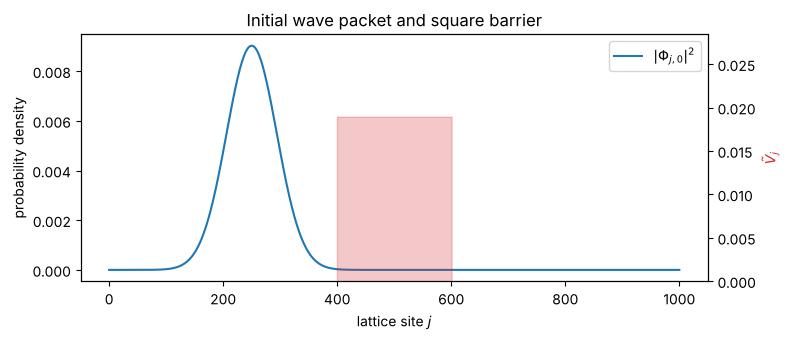

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Free parameters ------------------------------------------------------
N        = 1000   # number of lattice intervals (grid points j = 0..N)
n_cycles = 40     # oscillations of the wave over the lattice, 1 <= n_cycles <= N/4
lam      = 0.3    # barrier height in units of k0^2

assert 1 <= n_cycles <= N // 4, "n_cycles must lie in [1, N/4]"

# ---- Derived parameters (rescaled units: hbar = 1, m = 1/2, h = 1) -----------
k0 = 2 * np.pi * n_cycles / N        # k0~ = k0 * h
s  = 1.0 / (4 * k0**2)               # s~  = s / h^2
j  = np.arange(N + 1)                # lattice index

# ---- Initial wave function: Gaussian wave packet (eq. 24) --------------------
Phi0 = np.exp(1j * k0 * j) * np.exp(-8 * (4 * j - N)**2 / N**2)
Phi0[0] = Phi0[-1] = 0.0             # infinite walls
Phi0 /= np.sqrt(np.sum(np.abs(Phi0)**2))   # normalise so that sum |Phi|^2 = 1

# ---- Potential: square barrier on [2N/5, 3N/5] (eq. 25) ----------------------
j1, j2 = round(2 * N / 5), round(3 * N / 5)
V = np.zeros(N + 1)
V[j1:j2 + 1] = lam * k0**2

print(f"k0~ = {k0:.4f}   s~ = {s:.4f}   E = k0~^2 = {k0**2:.4f}   V0 = {lam*k0**2:.4f}")
print(f"barrier: j in [{j1}, {j2}]   group velocity = {2*k0*s:.3f} sites per time step")

# ---- Plot --------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(j, np.abs(Phi0)**2, color="C0", label=r"$|\Phi_{j,0}|^2$")
ax.set_xlabel("lattice site $j$"); ax.set_ylabel(r"probability density")
ax2 = ax.twinx()
ax2.fill_between(j, V, color="C3", alpha=0.25, step="mid")
ax2.set_ylabel(r"$\tilde V_j$", color="C3"); ax2.set_ylim(0, 1.5 * lam * k0**2 if lam > 0 else 1)
ax.set_title("Initial wave packet and square barrier"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

---
# 2. The algorithm

## 2.1 A first (bad) attempt: first-order Taylor expansion

The formal solution gives the one-step update $\Phi_{j,n+1}=e^{-isH}\Phi_{j,n}$ *(eq. 9)*. For small $s$ one can expand the exponential to first order and replace $H$ by its finite-difference version $H_D$:

$$
\Phi_{j,n+1}=\bigl[\,1-isH_D+O(sH_D)^2\bigr]\Phi_{j,n}, \qquad
H_Df_j=-\frac{1}{h^2}\,(f_{j+1}-2f_j+f_{j-1})+V_jf_j,
$$

where $V_j=V(jh)$ and the second derivative has error $O(h^2)$ *(eqs. 10–12)*.

This is simple and natural, but the operator $1-isH_D$ is **not unitary**. The discrete norm $\sum_j h|\Phi_{j,n}|^2$ then drifts as the iteration proceeds, which contradicts normalisation (3) and violates Born's interpretation.

## 2.2 The Cayley approximation: an exactly unitary scheme

The goal is an evolution operator of the same simplicity but **exactly unitary**. The Cayley approximation of the exponential does this *(eq. 13)*:

$$
e^{-isH}\;\approx\;\frac{1-isH_D/2}{1+isH_D/2}
\qquad\Longrightarrow\qquad
\Phi_{j,n+1}=\frac{1-isH_D/2}{1+isH_D/2}\,\Phi_{j,n}\quad\text{(eq. 14)} .
$$

* **Unitarity.** $H_D$ is a Hermitian matrix (with the Dirichlet boundary conditions). For each real eigenvalue $E$ of $H_D$, the factor $(1-isE/2)/(1+isE/2)$ has modulus exactly 1, so the norm is conserved to machine precision, independent of $s$ and $h$.
* **Accuracy.** It reproduces $e^{-isH}$ up to second order in $sH_D$ (the error is $O((sH_D)^3)$ per step), which is why the time step is chosen so that $\|H\|s<1$.

The scheme is **implicit**: applying $(1+isH_D/2)^{-1}$ means solving a linear system at each step.

## 2.3 Rewriting the step as a tridiagonal linear system

Using $\dfrac{1-x}{1+x}=\dfrac{2}{1+x}-1$ with $x=isH_D/2$, eq. (14) becomes *(eqs. 15–17)*:

$$
\Phi_{j,n+1}=\chi_{j,n}-\Phi_{j,n},
\qquad
\chi_{j,n}\equiv\frac{2}{1+isH_D/2}\,\Phi_{j,n}
\;\Longleftrightarrow\;
\left[1+\frac{isH_D}{2}\right]\chi_{j,n}=2\,\Phi_{j,n}.
$$

So each time step consists of **solving for $\chi$** and then computing $\Phi_{n+1}=\chi-\Phi_n$. Writing out $H_D$ with the rescaled quantities $\tilde s=s/h^2$ and $\tilde V_j=h^2V_j$, the linear system is *(eq. 18)*:

$$
\chi_{j+1,n}+\left[-2+\frac{2i}{\tilde s}-\tilde V_j\right]\chi_{j,n}+\chi_{j-1,n}=\frac{4i}{\tilde s}\,\Phi_{j,n}.
$$

This is a **tridiagonal system** for $j=1,\dots,N-1$ *(eq. 19)*:

$$
A_j^-\chi_{j-1,n}+A_j^0\chi_{j,n}+A_j^+\chi_{j+1,n}=b_{j,n},
$$

$$
A_j^-=1,\qquad A_j^0=-2+\frac{2i}{\tilde s}-\tilde V_j,\qquad A_j^+=1,\qquad b_{j,n}=\frac{4i}{\tilde s}\,\Phi_{j,n},
$$

with boundary conditions $\chi_0=\chi_N=0$. These guarantee $\Phi_0=\Phi_N=0$ at every time.

## 2.4 Solving the tridiagonal system (forward/backward recurrences)

The system is solved in $O(N)$ operations with the recurrence method (equivalent to the Thomas algorithm). Assume the solution has the form *(eq. 20)*:

$$
\chi_{j+1,n}=\alpha_j\,\chi_{j,n}+\beta_{j,n},\qquad j=0,\dots,N-1,
$$

with $\alpha_{N-1}=\beta_{N-1,n}=0$ so that $\chi_{N,n}=0$ is automatically satisfied. Substituting into (19) and identifying coefficients gives the recurrences *(eq. 22)*:

$$
\gamma_j^{-1}=A_j^0+A_j^+\alpha_j,\qquad
\alpha_{j-1}=-A_j^-\gamma_j,\qquad
\beta_{j-1,n}=\gamma_j\bigl(b_{j,n}-A_j^+\beta_{j,n}\bigr),
$$

evaluated **downwards** from $j=N-1$ to $j=1$. Two practical remarks:

* The $\alpha_j$ (and $\gamma_j$) depend only on the potential and on $\tilde s$, **not on time**, so they are computed **once** before the time loop.
* Only $\beta_{j,n}$ has to be recomputed at each step, since it contains $\Phi_{j,n}$ through $b_{j,n}$.

Once $\alpha$ and $\beta$ are known, $\chi_{j,n}$ follows from (20) by iterating **upwards** from $\chi_0=0$.

## 2.5 Summary of the algorithm

1. **Initialise.** Choose $N$, $n_\text{cycles}$ and $\lambda$. Generate $\tilde s$, $\tilde k_0$, $\tilde V_j$ and $\Phi_{j,0}$ (with $\Phi_{0,0}=\Phi_{N,0}=0$), and compute $\alpha_j$ (and $\gamma_j$) once.
2. **Compute $\beta_{j,n}$** with the downward recurrence (22).
3. **Compute $\chi_{j,n}$** with the upward recurrence (20), starting at $\chi_0=0$.
4. **Update the wave function:** $\Phi_{j,n+1}=\chi_{j,n}-\Phi_{j,n}$ (eq. 15).
5. Set $n\to n+1$ and go back to step 2.

At every step the norm $\sum_j|\Phi_{j,n}|^2$ should remain equal to 1 (the mandatory check in the problem set).

In [ ]:
def precompute_alpha_gamma(V, s):
    # alpha_j and gamma_j depend only on V and s~, so they are computed once.
    # Here A^- = A^+ = 1 and A^0_j = -2 + 2i/s~ - V~_j.
    N = len(V) - 1
    A0 = -2 + 2j / s - V
    alpha = np.zeros(N, dtype=complex)        # alpha_0 .. alpha_{N-1}, alpha_{N-1} = 0
    gamma = np.zeros(N, dtype=complex)        # gamma_1 .. gamma_{N-1}
    for jj in range(N - 1, 0, -1):            # j = N-1, ..., 1
        gamma[jj]     = 1.0 / (A0[jj] + alpha[jj])   # gamma_j^{-1} = A0_j + A+_j alpha_j
        alpha[jj - 1] = -gamma[jj]                   # alpha_{j-1} = -A-_j gamma_j
    return alpha, gamma


def cayley_step(Phi, alpha, gamma, s):
    # One time step: Phi_{n+1} = chi - Phi_n, with chi from the tridiagonal solve.
    N = len(Phi) - 1
    b = 4j * Phi / s                          # b_{j,n} = 4i Phi_{j,n} / s~

    beta = np.zeros(N, dtype=complex)         # beta_{N-1} = 0
    for jj in range(N - 1, 0, -1):            # downward recurrence (eq. 22)
        beta[jj - 1] = gamma[jj] * (b[jj] - beta[jj])

    chi = np.zeros(N + 1, dtype=complex)      # chi_0 = 0
    for jj in range(N):                       # upward recurrence (eq. 20)
        chi[jj + 1] = alpha[jj] * chi[jj] + beta[jj]

    return chi - Phi                          # eq. 15 (Phi_0 = Phi_N = 0 is preserved)


# ---- Time evolution ----------------------------------------------------------
n_steps = 250
snap_every = 50

alpha, gamma = precompute_alpha_gamma(V, s)

Phi = Phi0.copy()
norms = [np.sum(np.abs(Phi)**2)]
snapshots = {0: Phi.copy()}
for n in range(1, n_steps + 1):
    Phi = cayley_step(Phi, alpha, gamma, s)
    norms.append(np.sum(np.abs(Phi)**2))
    if n % snap_every == 0:
        snapshots[n] = Phi.copy()

norms = np.array(norms)
print(f"initial norm        : {norms[0]:.15f}")
print(f"final norm          : {norms[-1]:.15f}")
print(f"max |norm - 1|      : {np.max(np.abs(norms - 1)):.2e}")

initial norm        : 1.000000000000000
final norm          : 0.999999999999933
max |norm - 1|      : 6.65e-14


left of barrier : 0.0085
inside barrier  : 0.0387
right of barrier: 0.9528


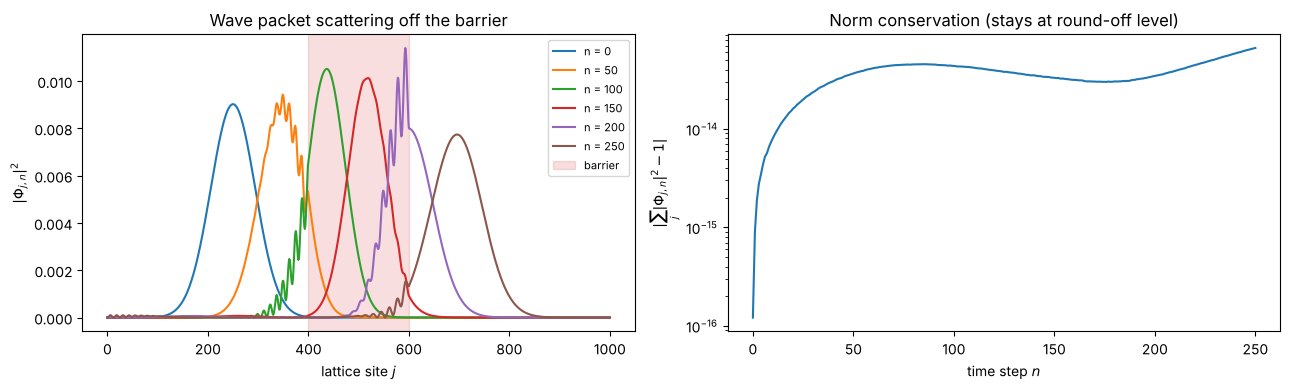

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Snapshots of the probability density
ax = axes[0]
for n, P in snapshots.items():
    ax.plot(j, np.abs(P)**2, label=f"n = {n}")
ax.axvspan(j1, j2, color="C3", alpha=0.15, label="barrier")
ax.set_xlabel("lattice site $j$"); ax.set_ylabel(r"$|\Phi_{j,n}|^2$")
ax.set_title("Wave packet scattering off the barrier"); ax.legend(fontsize=8)

# Norm conservation
ax = axes[1]
ax.semilogy(np.arange(n_steps + 1), np.abs(norms - 1) + 1e-17)
ax.set_xlabel("time step $n$"); ax.set_ylabel(r"$|\sum_j|\Phi_{j,n}|^2 - 1|$")
ax.set_title("Norm conservation (stays at round-off level)")

plt.tight_layout(); plt.show()

# Where is the probability at the final time?
P = np.abs(Phi)**2
print(f"left of barrier : {P[:j1].sum():.4f}")
print(f"inside barrier  : {P[j1:j2+1].sum():.4f}")
print(f"right of barrier: {P[j2+1:].sum():.4f}")

## 2.6 Notes

* The norm is conserved to round-off level because the Cayley operator is exactly unitary. A first-order Taylor update would show the norm drifting away from 1.
* All the work per step is $O(N)$ (two sweeps over the lattice), and the $\alpha,\gamma$ coefficients are only computed once.
* The simulation time must be short enough that the packet does not reach the right-hand wall and reflect back (here $n=250$ steps for $N=1000$).
* Changing $\lambda$ changes the reflected and transmitted fractions, the basis for the transmission-coefficient study proposed in the problem set.